In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score, f1_score
#from train_linear_model import split_dataset
#from datatypes import CLEAN_SQF
import warnings

# Silence warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

In [15]:
def load_and_split_data(): 
    data_path = "../clean-data/cleaned_sqf.csv" 
    
    clean_df = pd.read_csv(data_path)
    
    features = clean_df.columns.difference(["USE_OF_FORCE_FLAG"]).values
    X = clean_df[features]
    y = clean_df["USE_OF_FORCE_FLAG"]
    
    return train_test_split(X, y, test_size=0.2, random_state=123)

In [16]:
X_train, X_test, y_train, y_test = load_and_split_data()
depths = [3, 5, 10, 20, None]
metrics = ["recall", "f1"]

 [Decision Tree] CV Fold Scores vs Real Hold-out Test (RECALL) 


,Max_Depth,CV_Train,CV_Valid (Fold),Real_Train (Full),Real_Test (Hold-out)
0,3,0.700924,0.700151,0.693119,0.693192
1,5,0.751319,0.747632,0.741262,0.747126
2,10,0.734115,0.672461,0.721697,0.691424
3,20,0.738568,0.562330,0.751374,0.626879
4,None,0.738898,0.487363,0.733128,0.523431


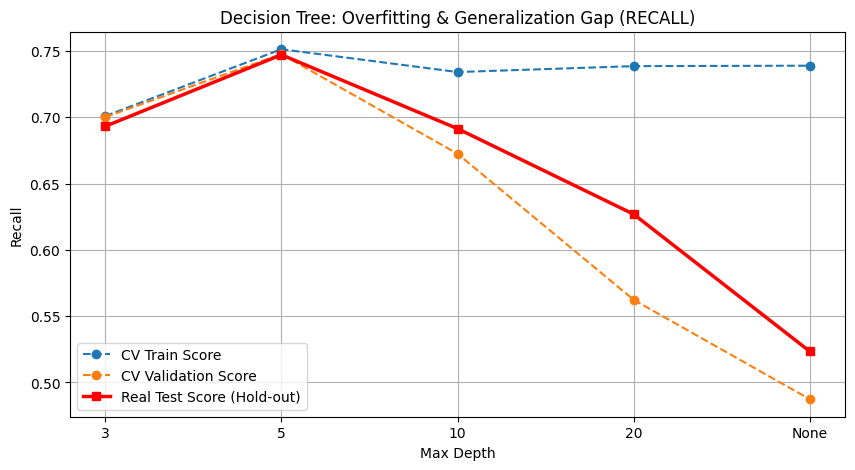

 [Decision Tree] CV Fold Scores vs Real Hold-out Test (F1) 


,Max_Depth,CV_Train,CV_Valid (Fold),Real_Train (Full),Real_Test (Hold-out)
0,3,0.405383,0.404890,0.403868,0.403292
1,5,0.415143,0.412456,0.415015,0.414520
2,10,0.440840,0.403639,0.440494,0.417512
3,20,0.511704,0.390504,0.492153,0.406187
4,None,0.569451,0.378733,0.556111,0.397449


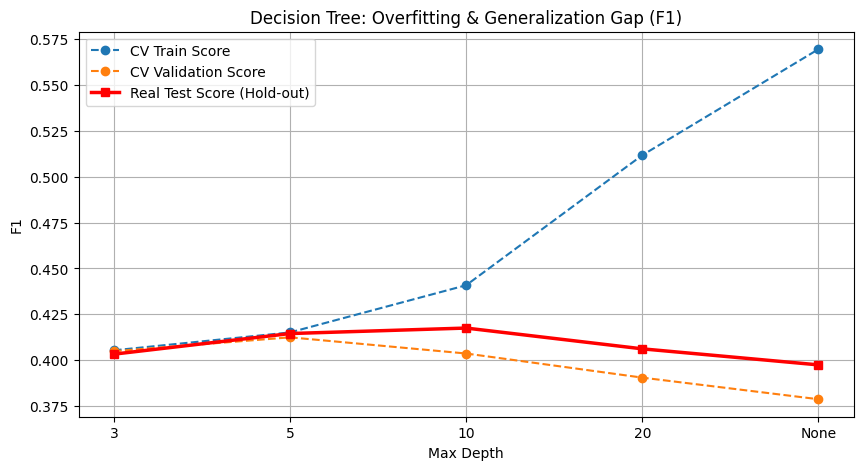

In [ ]:
for metric in metrics:
    print(f" [Decision Tree] Train vs. Test ({metric.upper()}) ")
    
    
    dt_summary = []
    score_fn = recall_score if metric == "recall" else f1_score
    
    for d in depths:
        # if data imbalanced, class_weight="balanced" 
        dt = DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=123)
        
        # Cross Validation (Validation Fold)
        cv_scores = cross_validate(dt, X_train, y_train, cv=5, return_train_score=True, scoring=metric)
        
        # train model
        dt.fit(X_train, y_train)
        train_pred = dt.predict(X_train)
        test_pred = dt.predict(X_test)
        
        real_train_score = score_fn(y_train, train_pred)
        real_test_score = score_fn(y_test, test_pred)
        
        dt_summary.append({
            "Max_Depth": "None" if d is None else d,
            "CV_Train": np.mean(cv_scores["train_score"]),
            "CV_Valid (Fold)": np.mean(cv_scores["test_score"]), 
            "Real_Train (Full)": real_train_score,             
            "Real_Test (Hold-out)": real_test_score            
        })
    
    dt_df = pd.DataFrame(dt_summary)
    display(dt_df)
    
    # graph
    plt.plot(dt_df["Max_Depth"].astype(str), dt_df["CV_Train"], label="CV Train Score", marker='o', linestyle='--')
    plt.plot(dt_df["Max_Depth"].astype(str), dt_df["CV_Valid (Fold)"], label="CV Validation Score", marker='o', linestyle='--')
    plt.plot(dt_df["Max_Depth"].astype(str), dt_df["Real_Test (Hold-out)"], label="Real Test Score (Hold-out)", marker='s', color='red', linewidth=2.5)
    plt.title(f"Decision Tree: Overfitting & Generalization Gap ({metric.upper()})")
    plt.xlabel("Max Depth")
    plt.ylabel(metric.capitalize())
    plt.legend()
    plt.grid(True)
    plt.show()


 [Random Forest] Internal CV Folds vs Real Hold-out Test (RECALL) 


,Max_Depth,CV_Train,CV_Valid (Fold),Real_Train (Full),Real_Test (Hold-out)
0,3,0.673225,0.670253,0.675093,0.681698
1,5,0.692460,0.685206,0.692900,0.699381
2,10,0.720818,0.648493,0.721917,0.674624
3,20,0.704935,0.464500,0.702132,0.500442
4,None,0.678830,0.412401,0.670257,0.449160


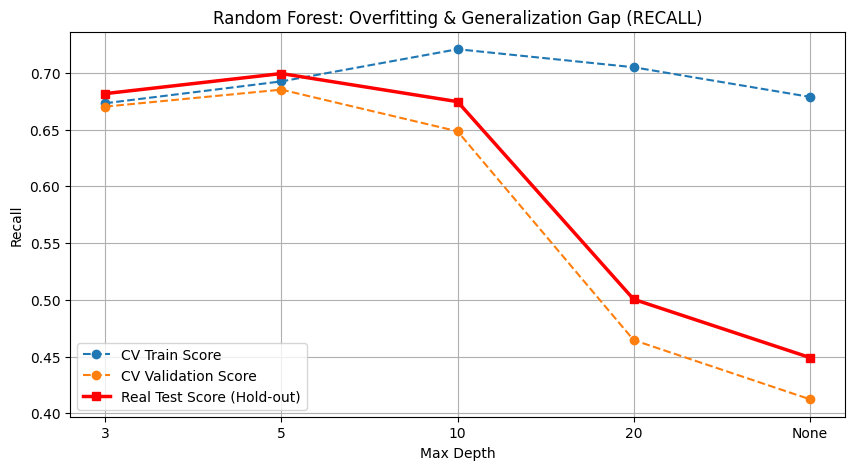


 [Random Forest] Internal CV Folds vs Real Hold-out Test (F1) 


,Max_Depth,CV_Train,CV_Valid (Fold),Real_Train (Full),Real_Test (Hold-out)
0,3,0.411710,0.409985,0.411745,0.413294
1,5,0.417230,0.413108,0.416573,0.418408
2,10,0.458205,0.412036,0.451037,0.414787
3,20,0.561504,0.380805,0.546590,0.392103
4,None,0.572315,0.361966,0.558630,0.381525


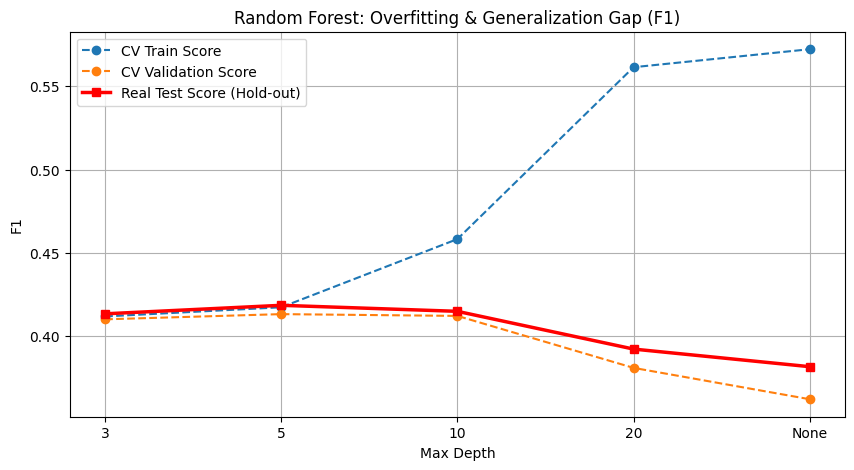

In [ ]:
for metric in metrics:
    print(f" [Random Forest] Internal CV Folds vs Real Hold-out Test ({metric.upper()}) ")
    

    rf_summary = []
    score_fn = recall_score if metric == "recall" else f1_score
    
    for d in depths:
        # class_weight="balanced" and 100 trees
        rf = RandomForestClassifier(n_estimators=100, max_depth=d, class_weight="balanced", random_state=123)
        
        # Cross Validation
        cv_scores = cross_validate(rf, X_train, y_train, cv=5, return_train_score=True, scoring=metric)
        
        # full data train and Unseen data Test
        rf.fit(X_train, y_train)
        train_pred = rf.predict(X_train)
        test_pred = rf.predict(X_test)
        
        real_train_score = score_fn(y_train, train_pred)
        real_test_score = score_fn(y_test, test_pred)
        
        rf_summary.append({
            "Max_Depth": "None" if d is None else d,
            "CV_Train": np.mean(cv_scores["train_score"]),
            "CV_Valid (Fold)": np.mean(cv_scores["test_score"]),
            "Real_Train (Full)": real_train_score,
            "Real_Test (Hold-out)": real_test_score
        })
    
    rf_df = pd.DataFrame(rf_summary)
    display(rf_df)
    
    #graph
    plt.figure(figsize=(10, 5))
    plt.plot(rf_df["Max_Depth"].astype(str), rf_df["CV_Train"], label="CV Train Score", marker='o', linestyle='--')
    plt.plot(rf_df["Max_Depth"].astype(str), rf_df["CV_Valid (Fold)"], label="CV Validation Score", marker='o', linestyle='--')
    plt.plot(rf_df["Max_Depth"].astype(str), rf_df["Real_Test (Hold-out)"], label="Real Test Score (Hold-out)", marker='s', color='red', linewidth=2.5)
    plt.title(f"Random Forest: Overfitting & Generalization Gap ({metric.upper()})")
    plt.xlabel("Max Depth")
    plt.ylabel(metric.capitalize())
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
dt_summary.append({
    "Max_Depth": "None" if d is None else d,
    "CV_Train": np.mean(cv_scores["train_score"]),       
    "CV_Valid (Fold)": np.mean(cv_scores["test_score"]), 
    "Real_Test (Hold-out)": real_test_score             
})